In [73]:
import pandas as pd
import xarray as xr
import seaborn as sns
import glob
import dask
import matplotlib.pyplot as plt
import folium
import gsw
from sklearn.preprocessing import StandardScaler

 Ouvrir un fichier NetCDF
ds = xr.open_dataset("chemin/vers/votre_fichier.nc")

 Afficher les informations sur le dataset
print(ds)



In [74]:
glob.glob('/runtime/data/7901038/*')[-1]

'/runtime/data/7901038/GL_PR_PF_7901038_20230909.nc'

In [75]:
path = glob.glob('/runtime/data/7901038/*')[-1]

In [76]:
ds = xr.open_dataset(path)

In [77]:
ds

<xarray.Dataset> Size: 9kB
Dimensions:                   (TIME: 1, LATITUDE: 1, LONGITUDE: 1, POSITION: 1,
                               DEPTH: 198)
Coordinates:
  * TIME                      (TIME) datetime64[ns] 8B 2023-09-09T15:04:00
  * LATITUDE                  (LATITUDE) float32 4B 81.78
  * LONGITUDE                 (LONGITUDE) float32 4B 37.31
Dimensions without coordinates: POSITION, DEPTH
Data variables: (12/16)
    TIME_QC                   (TIME) float32 4B ...
    POSITION_QC               (POSITION) float32 4B ...
    DC_REFERENCE              (TIME) object 8B ...
    DIRECTION                 (TIME) object 8B ...
    VERTICAL_SAMPLING_SCHEME  (TIME) object 8B ...
    PRES                      (TIME, DEPTH) float32 792B ...
    ...                        ...
    PSAL_QC                   (TIME, DEPTH) float32 792B ...
    TIME_QC_MM                (TIME) float32 4B ...
    POSITION_QC_MM            (POSITION) float32 4B ...
    PRES_QC_MM                (TIME, DEPTH) float32 792B ...
    TEMP_QC_MM                (TIME, DEPTH) float32 792B ...
    PSAL_QC_MM                (TIME, DEPTH) float32 792B ...
Attributes: (12/49)
    platform_code:                  7901038
    platform_name:                  ARVOR Profiling Float
    wmo_platform_code:              7901038
    ices_platform_code:              
    coriolis_platform_code:         7901038
    site_code:                       
    ...                             ...
    id:                             GL_PR_PF_7901038_20230909
    netcdf_version:                 netCDF-4 classic model
    format_version:                 1.4
    Conventions:                    CF-1.6 Copernicus-InSituTAC-FormatManual-...
    date_update:                    2023-09-09T18:01:25Z
    history:                        2023-09-09T18:01:25Z : Creation

In [78]:
latitude = ds['LATITUDE'].values
longitude = ds['LONGITUDE'].values

In [79]:
temperature = ds['TEMP'].values
pression = ds['PRES'].values
salinite = ds['PSAL']

In [80]:
temperature

array([[1.01100005, 1.10900005, 1.37900007, 1.73800008, 1.97800009,
        2.22700011, 2.23200011, 2.21700011, 2.27600011, 2.28400011,
        2.32300011, 2.42800012, 2.53100012, 2.60200012, 2.65900013,
        2.70000013, 2.70900013, 2.75400013, 2.86400014, 2.78300013,
        2.63000012, 2.63300013, 2.63400013, 2.57600012, 2.51200012,
        2.50900012, 2.50800012, 2.44600012, 2.32600011, 2.1630001 ,
        2.0800001 , 1.81800009, 1.84300009, 1.73600008, 1.71500008,
        1.73400008, 1.69000008, 1.62600008, 1.44200007, 1.27300006,
        1.17900006, 1.12200005, 1.16100006, 1.21600006, 1.25700006,
        1.28200006, 1.56900007, 1.57900007, 1.58900008, 1.95400009,
        2.26700011, 2.2100001 , 2.21900011, 2.1500001 , 2.1570001 ,
        2.0710001 , 2.0630001 , 2.1040001 , 2.1120001 , 2.29300011,
        2.31900011, 2.35900011, 2.40900011, 2.52400012, 2.57700012,
        2.66300013, 2.75800013, 2.75400013, 2.76500013, 2.79100013,
        2.80100013, 2.81200013, 2.76400013, 2.65

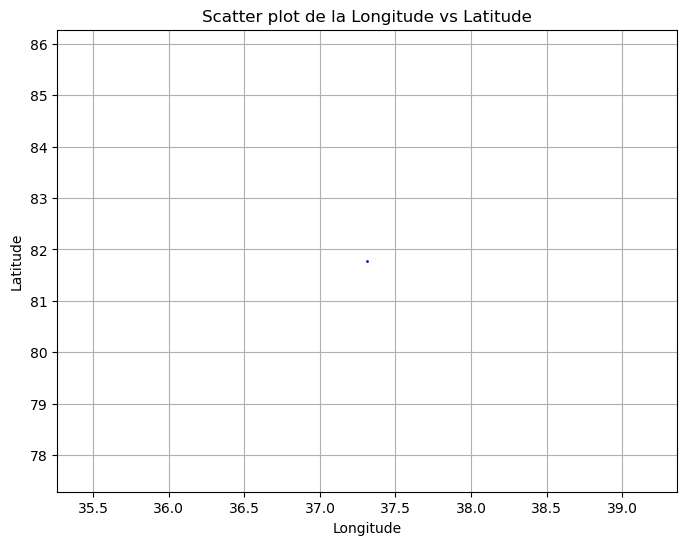

In [81]:
plt.figure(figsize=(8, 6))
plt.scatter(longitude, latitude, color='blue', s=1)  # 's=1' pour des points petits
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Scatter plot de la Longitude vs Latitude')
plt.grid(True)
plt.show()

In [82]:
m = folium.Map(location=[latitude.mean(), longitude.mean()], zoom_start=6)
for lat, lon in zip(latitude, longitude):
    folium.Marker([lat, lon]).add_to(m)

In [83]:
m

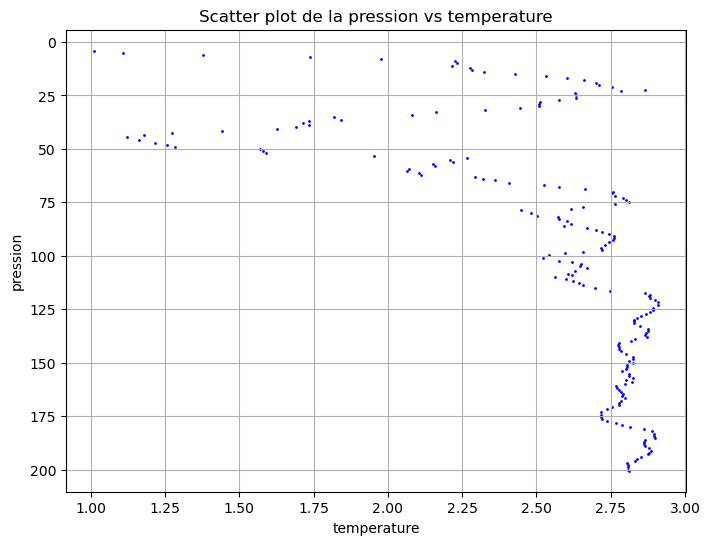

In [84]:
plt.figure(figsize=(8, 6))
plt.scatter(temperature, pression, color='blue', s=1)  
plt.xlabel('temperature')
plt.ylabel('pression')
plt.title('Scatter plot de la pression vs temperature')
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()

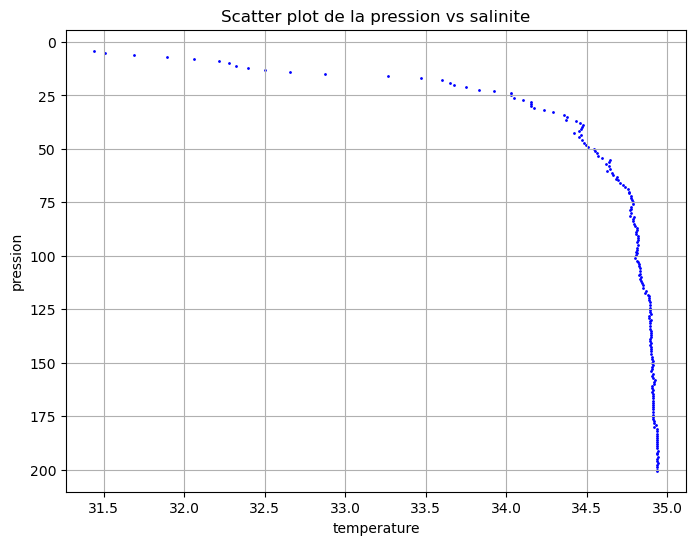

In [85]:
plt.figure(figsize=(8, 6))
plt.scatter(salinite, pression, color='blue', s=1)  
plt.xlabel('temperature')
plt.ylabel('pression')
plt.title('Scatter plot de la pression vs salinite')
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()

In [86]:
ds.attrs

{'platform_code': '7901038',
 'platform_name': 'ARVOR Profiling Float',
 'wmo_platform_code': '7901038',
 'ices_platform_code': ' ',
 'coriolis_platform_code': '7901038',
 'site_code': ' ',
 'comment': ' ',
 'source': 'drifting subsurface profiling float',
 'source_platform_category_code': '46',
 'institution': "IFREMER Institut Francais de Recherche pour l'Exploitation de la Mer",
 'institution_edmo_code': '1054',
 'institution_references': ' ',
 'naming_authority': 'Copernicus Marine In Situ',
 'title': 'Global Ocean - In Situ Observation Copernicus',
 'summary': ' ',
 'data_mode': 'R',
 'wmo_inst_type': '844',
 'area': 'Global Ocean',
 'geospatial_lat_min': '81.78066',
 'geospatial_lat_max': '81.78066',
 'geospatial_lon_min': '37.31156',
 'geospatial_lon_max': '37.31156',
 'geospatial_vertical_min': '4.10',
 'geospatial_vertical_max': '200.50',
 'time_coverage_start': '2023-09-09T15:04:00Z',
 'time_coverage_end': '2023-09-09T15:04:00Z',
 'data_type': 'OceanSITES vertical profile',
 

In [87]:
dict_att = ds.attrs

In [88]:
df = pd.DataFrame([ds.attrs])

In [89]:
df

,platform_code,platform_name,wmo_platform_code,ices_platform_code,coriolis_platform_code,site_code,comment,source,source_platform_category_code,institution,...,pi_name,qc_manual,contact,author,id,netcdf_version,format_version,Conventions,date_update,history
0,7901038,ARVOR Profiling Float,7901038,,7901038,,,drifting subsurface profiling float,46,IFREMER Institut Francais de Recherche pour l'...,...,Camille LIQUE,Recommendations for in-situ data Near Real Tim...,cmems-service@ifremer.fr,Coriolis for Copernicus Marine service,GL_PR_PF_7901038_20230909,netCDF-4 classic model,1.4,CF-1.6 Copernicus-InSituTAC-FormatManual-1.43 ...,2023-09-09T18:01:25Z,2023-09-09T18:01:25Z : Creation


In [90]:
date_array = ds['TIME'].values

In [91]:
import numpy as np
from datetime import datetime

In [92]:
date_obj = date_array[0].astype('M8[ms]').astype(datetime)  # Conversion en datetime
formatted_date = date_obj.strftime("%B %d, %Y")  # Formatage en anglais

print(formatted_date)

September 09, 2023


# test avec gibbs sea water

In [93]:
#salinite.values.flatten()
#latitude
temperature.flatten()
pression.flatten()

array([  4.1,   5. ,   5.9,   7.1,   7.9,   8.9,  10. ,  11.1,  12. ,
        13. ,  14.1,  15.1,  16. ,  17. ,  18. ,  19. ,  20. ,  20.9,
        22.3,  23.1,  24.1,  25. ,  26. ,  27. ,  28.1,  28.9,  29.9,
        31.1,  31.9,  32.7,  34. ,  35.3,  36.3,  37.1,  38.1,  39. ,
        39.9,  40.9,  41.8,  42.7,  43.7,  44.6,  45.9,  47.3,  48.3,
        49.2,  50.2,  51.2,  52.1,  53.1,  54.1,  55.1,  56.1,  57.1,
        58.2,  59.2,  60.2,  61.2,  62.2,  63.1,  63.9,  64.7,  65.8,
        67. ,  67.7,  68.8,  70. ,  70.7,  71.9,  73.1,  73.9,  74.7,
        75.9,  77.1,  77.9,  78.7,  80. ,  81.2,  82. ,  82.8,  83.7,
        84.9,  86.2,  87.1,  88. ,  88.9,  89.8,  90.7,  91.7,  92.6,
        93.5,  94.9,  96.3,  97.2,  98. ,  98.9,  99.8, 101. , 102.3,
       103.1, 104. , 104.8, 105.7, 107. , 108.3, 109.2, 110.1, 111. ,
       111.8, 112.7, 113.6, 114.9, 116.3, 117.2, 118.1, 118.9, 119.8,
       120.7, 121.7, 122.9, 124.3, 125.2, 126.1, 127.1, 128. , 128.9,
       129.8, 130.7,

In [94]:
latitude

array([81.78066], dtype=float32)

In [95]:
def calculate_salinity_density(ds, latitude_array, longitude_array):
    latitude = float(latitude_array[0])
    longitude = float(longitude_array[0])

    sp = ds['PSAL'].values.flatten()  
    t = ds['TEMP'].values.flatten()   
    p = ds['PRES'].values.flatten()   


    
    # salinité absolue
    sa = gsw.SA_from_SP(sp, p, longitude, latitude)
    # température conservative
    ct = gsw.CT_from_t(sa, t, p)
    # densité potentielle
    sigma0 = gsw.sigma0(sa, ct)
    '''
    Calculates the oxygen concentration expected at equilibrium with air at an Absolute 
    Pressure of 101325 Pa (sea pressure of 0 dbar) including saturated water vapor. 
    This function uses the solubility coefficients derived from the data of Benson and Krause (1984),
    as fitted by Garcia and Gordon (1992, 1993).
    '''
    O2sol = gsw.O2sol(sa, ct, p, latitude, longitude)
    # Création du DataFrame
    df = pd.DataFrame({
        'PSAL': sp,
        'Temperature in situ': t,
        'PRES': p,
        'SA ( salinité absolue)': sa,
        'sigma0 (potential density anomaly)': sigma0,
        'O2sol' : O2sol,
        'latitude': latitude,
        'longitude': longitude
    })

    return df


In [96]:
df = calculate_salinity_density(ds,latitude, longitude)

In [97]:
from sklearn.cluster import KMeans

In [98]:
columns_to_cluster = ["PSAL", "Temperature in situ", "SA ( salinité absolue)", 
                      "sigma0 (potential density anomaly)", "O2sol"]
X = df[columns_to_cluster]

In [99]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [100]:
inertia = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

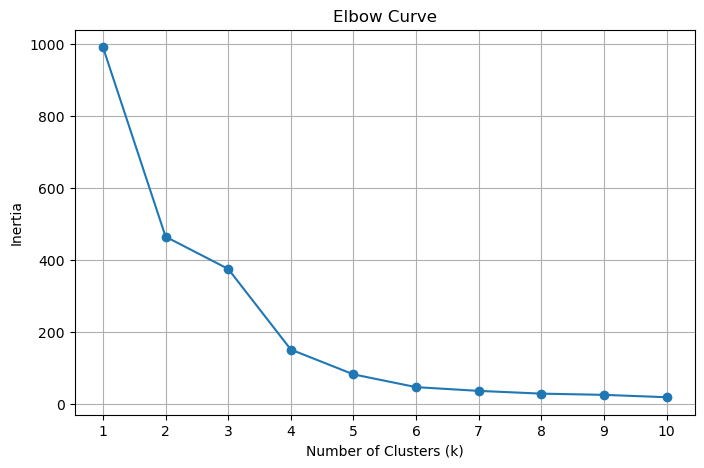

In [101]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o')
plt.title("Elbow Curve")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

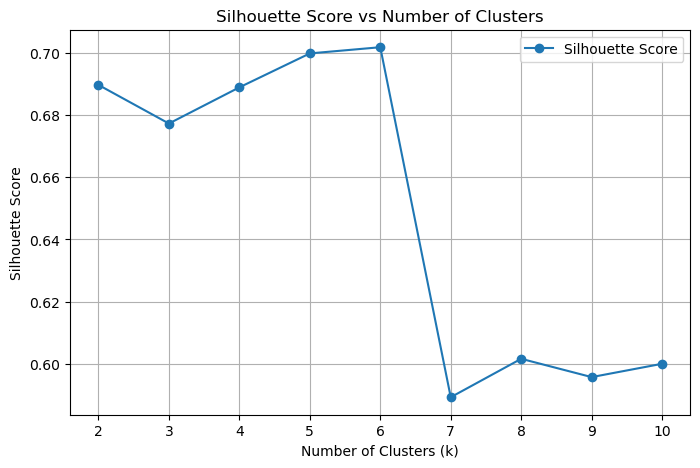

In [102]:
from sklearn.metrics import silhouette_score

silhouette_scores = []
for k in k_values[1:]:  # Silhouette n'est pas défini pour k=1
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Tracer l'indice de silhouette
plt.figure(figsize=(8, 5))
plt.plot(k_values[1:], silhouette_scores, marker='o', label='Silhouette Score')
plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.legend()
plt.show()


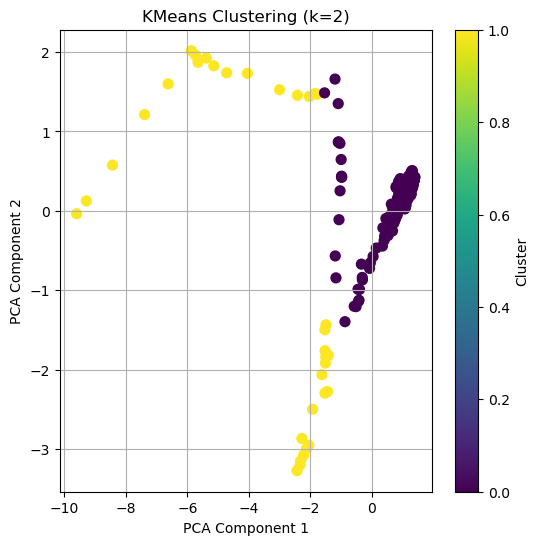

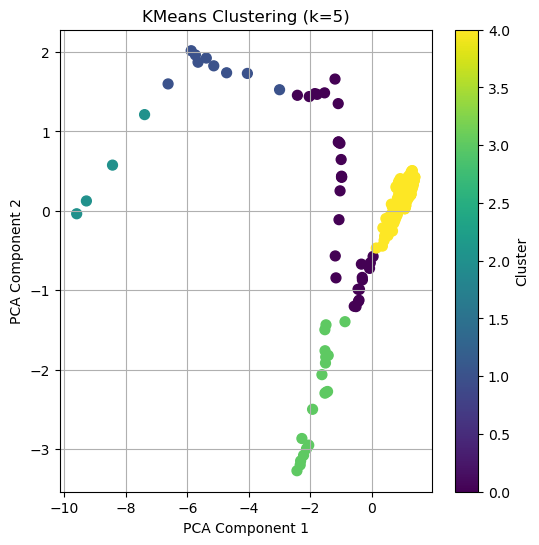

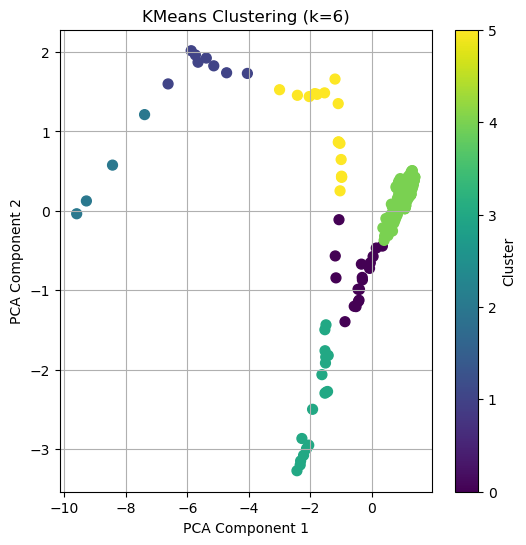

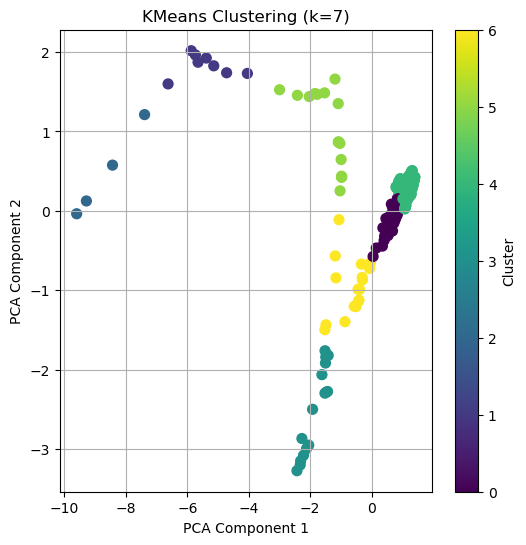

In [103]:
from sklearn.decomposition import PCA

# Appliquer PCA pour réduire à 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualiser les clusters pour différents k
for k in [2, 5, 6, 7]:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    plt.figure(figsize=(6, 6))
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=50)
    plt.title(f"KMeans Clustering (k={k})")
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(True)
    plt.show()


In [104]:
# Appliquer KMeans avec k=5
kmeans_5 = KMeans(n_clusters=5, random_state=42)
df['cluster_k5'] = kmeans_5.fit_predict(X_scaled)

# Appliquer KMeans avec k=7
kmeans_7 = KMeans(n_clusters=7, random_state=42)
df['cluster_k7'] = kmeans_7.fit_predict(X_scaled)

# Afficher la dataframe mise à jour
print(df)

          PSAL  Temperature in situ        PRES  SA ( salinité absolue)  \
0    31.441001                1.011    4.100000               31.590464   
1    31.509001                1.109    5.000000               31.658780   
2    31.689002                1.379    5.900000               31.839628   
3    31.894002                1.738    7.100000               32.045592   
4    32.062002                1.978    7.900000               32.214384   
..         ...                  ...         ...                     ...   
193  34.942002                2.805  197.100006               35.108667   
194  34.939002                2.809  197.800003               35.105654   
195  34.939002                2.808  198.800003               35.105656   
196  34.940002                2.807  200.000000               35.106663   
197  34.940002                2.811  200.500000               35.106664   

     sigma0 (potential density anomaly)       O2sol   latitude  longitude  \
0                     

In [105]:
df.head()

,PSAL,Temperature in situ,PRES,SA ( salinité absolue),sigma0 (potential density anomaly),O2sol,latitude,longitude,cluster_k5,cluster_k7
0,31.441001,1.011,4.1,31.590464,25.186642,348.418452,81.780663,37.311562,2,2
1,31.509001,1.109,5.0,31.658780,25.235574,347.359287,81.780663,37.311562,2,2
2,31.689002,1.379,5.9,31.839628,25.363641,344.486892,81.780663,37.311562,2,2
3,31.894002,1.738,7.1,32.045592,25.504495,340.816832,81.780663,37.311562,2,2
4,32.062002,1.978,7.9,32.214384,25.622268,338.318676,81.780663,37.311562,1,1


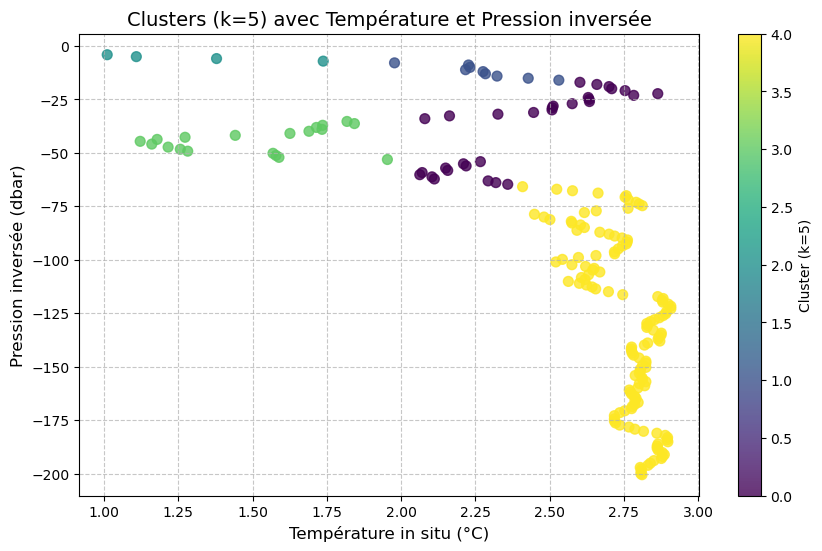

In [106]:



df['PRES_inverted'] = -df['PRES']  


plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    df['Temperature in situ'], df['PRES_inverted'], 
    c=df['cluster_k5'], cmap='viridis', s=50, alpha=0.8
)
plt.colorbar(scatter, label='Cluster (k=5)')
plt.title("Clusters (k=5) avec Température et Pression inversée", fontsize=14)
plt.xlabel("Température in situ (°C)", fontsize=12)
plt.ylabel("Pression inversée (dbar)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


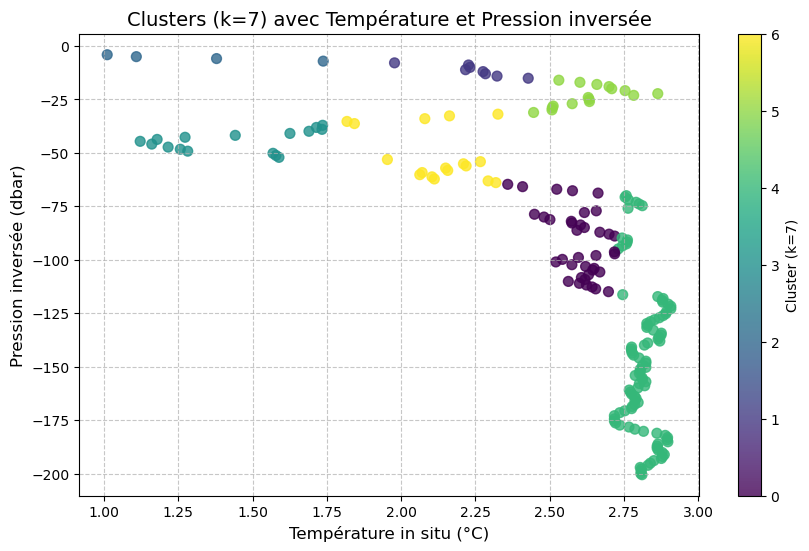

In [109]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    df['Temperature in situ'], df['PRES_inverted'], 
    c=df['cluster_k7'], cmap='viridis', s=50, alpha=0.8
)
plt.colorbar(scatter, label='Cluster (k=7)')
plt.title("Clusters (k=7) avec Température et Pression inversée", fontsize=14)
plt.xlabel("Température in situ (°C)", fontsize=12)
plt.ylabel("Pression inversée (dbar)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [108]:
df.columns

Index(['PSAL', 'Temperature in situ', 'PRES', 'SA ( salinité absolue)',
       'sigma0 (potential density anomaly)', 'O2sol', 'latitude', 'longitude',
       'cluster_k5', 'cluster_k7', 'PRES_inverted'],
      dtype='object')

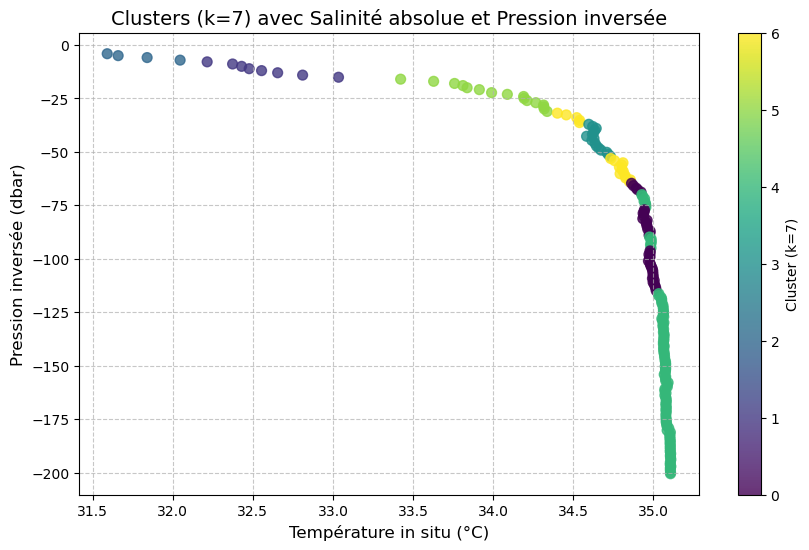

In [110]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    df['SA ( salinité absolue)'], df['PRES_inverted'], 
    c=df['cluster_k7'], cmap='viridis', s=50, alpha=0.8
)
plt.colorbar(scatter, label='Cluster (k=7)')
plt.title("Clusters (k=7) avec Salinité absolue et Pression inversée", fontsize=14)
plt.xlabel("Température in situ (°C)", fontsize=12)
plt.ylabel("Pression inversée (dbar)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

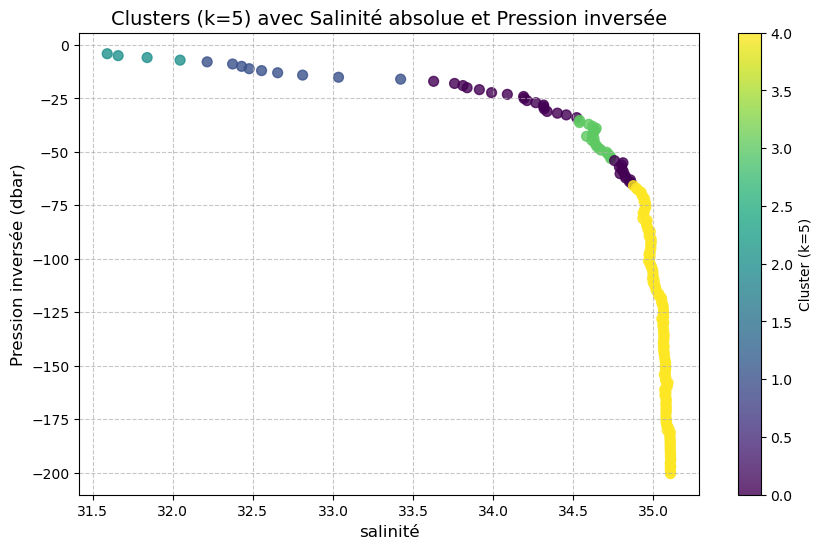

In [112]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    df['SA ( salinité absolue)'], df['PRES_inverted'], 
    c=df['cluster_k5'], cmap='viridis', s=50, alpha=0.8
)
plt.colorbar(scatter, label='Cluster (k=5)')
plt.title("Clusters (k=5) avec Salinité absolue et Pression inversée", fontsize=14)
plt.xlabel("salinité", fontsize=12)
plt.ylabel("Pression inversée (dbar)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [113]:
df.columns

Index(['PSAL', 'Temperature in situ', 'PRES', 'SA ( salinité absolue)',
       'sigma0 (potential density anomaly)', 'O2sol', 'latitude', 'longitude',
       'cluster_k5', 'cluster_k7', 'PRES_inverted'],
      dtype='object')

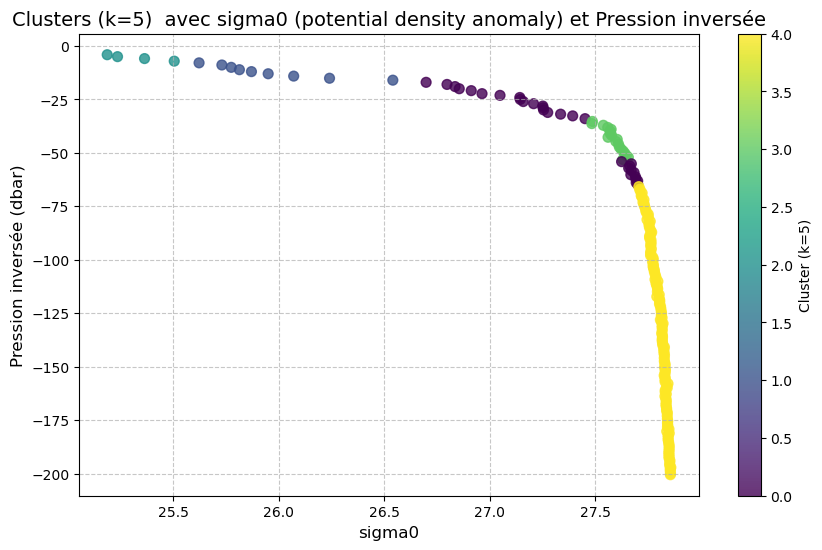

In [114]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    df['sigma0 (potential density anomaly)'], df['PRES_inverted'], 
    c=df['cluster_k5'], cmap='viridis', s=50, alpha=0.8
)
plt.colorbar(scatter, label='Cluster (k=5)')
plt.title("Clusters (k=5)  avec sigma0 (potential density anomaly) et Pression inversée", fontsize=14)
plt.xlabel("sigma0", fontsize=12)
plt.ylabel("Pression inversée (dbar)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()